# House Prices: from baseline to blend, one measured step at a time

**Task.** Predict the sale price of 1,459 houses in Ames, Iowa, from 79 descriptive columns
(size, age, quality, location, ...). We learn from 1,460 houses whose prices we know.

**Metric.** Kaggle scores the RMSE between the *log* of our predicted price and the *log* of the
true price. Working in logs means a 10% miss counts the same on a cheap house as on an
expensive one.

**How this notebook is organised.** Part 1 explores the data. Part 2 builds a baseline and the
cross-validation tools. Part 3 adds feature engineering one step at a time. Part 4 compares
models. Part 5 blends them. Every step's score goes into one results table, so the whole
pathway can be read off at the end.

## Part 1: Exploratory data analysis (EDA)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# On Kaggle the data sits under /kaggle/input; locally it sits next to this repo's v2 folder.
CANDIDATES = [Path("/kaggle/input/house-prices-advanced-regression-techniques"),
              Path("../house-prices-advanced-regression-techniques"),
              Path("house-prices-advanced-regression-techniques")]
DATA_DIR = next(path for path in CANDIDATES if (path / "train.csv").exists())
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("results")
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)


def read_csv(name):
    # The string "None" is a real category (e.g. MasVnrType = no masonry veneer).
    # Only "NA" and empty cells mean missing.
    return pd.read_csv(DATA_DIR / name, keep_default_na=False, na_values=["NA", ""])


train = read_csv("train.csv")
test = read_csv("test.csv")
sample = read_csv("sample_submission.csv")
print("train:", train.shape, " test:", test.shape)

train: (1460, 81)  test: (1459, 80)


### 1.1 First look
`train` has 81 columns: `Id`, 79 descriptive columns, and the target `SalePrice`.
`test` has the same columns except `SalePrice`, which is what we must predict.

In [2]:
print(train.dtypes.value_counts())
train.head()

object     43
int64      35
float64     3
Name: count, dtype: int64


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 1.2 The target: SalePrice
Most houses sell for $130k–$215k, but a long tail runs up to $755k. A *right-skewed*
target like this pulls a linear model towards the few expensive houses. Taking the log
makes the distribution almost symmetric, and it is also the scale Kaggle scores on.

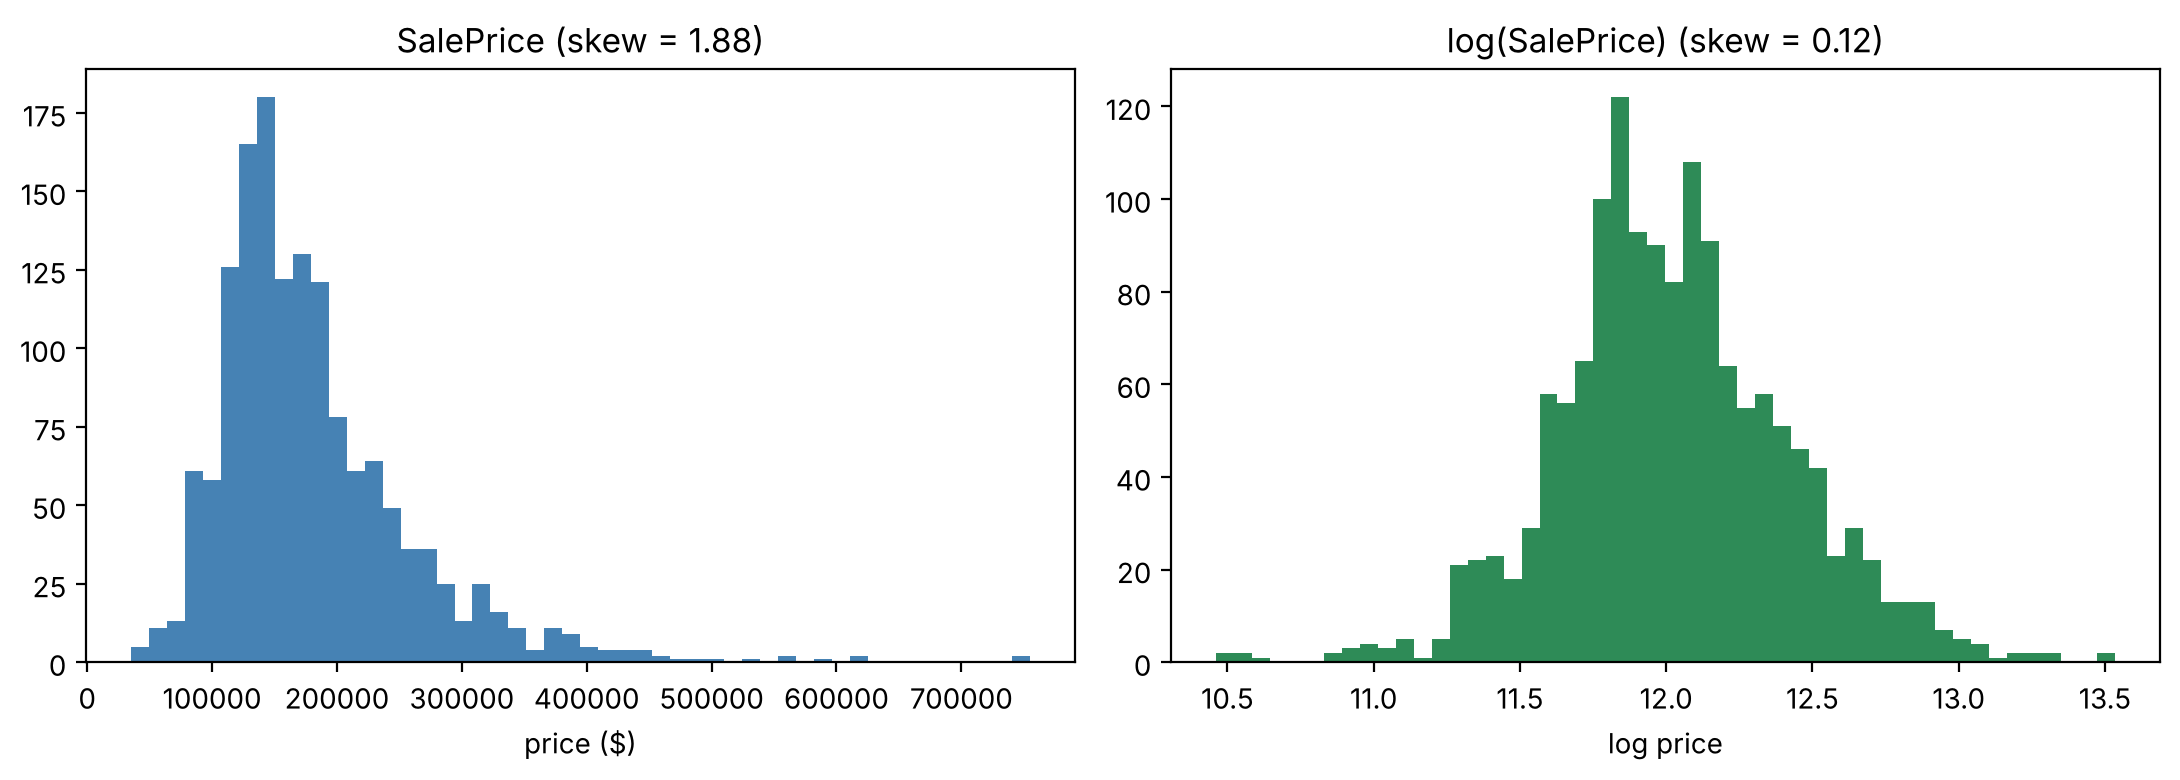

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train.SalePrice, bins=50, color="steelblue")
axes[0].set(title=f"SalePrice (skew = {train.SalePrice.skew():.2f})", xlabel="price ($)")
axes[1].hist(np.log(train.SalePrice), bins=50, color="seagreen")
axes[1].set(title=f"log(SalePrice) (skew = {np.log(train.SalePrice).skew():.2f})", xlabel="log price")
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "01_saleprice_distribution.png", dpi=120)
plt.show()

### 1.3 Missing values: two very different kinds
`data_description.txt` says that for many columns **NA means "this house doesn't have one"**:
no pool, no garage, no basement, no fence. That is information, not a gap.
For other columns (e.g. `LotFrontage`), NA really means *we don't know*.
Part 3 treats the two kinds differently.

A few columns are missing **only in test** (e.g. `MSZoning`, `GarageCars`). Our pipeline
must cope with gaps it never saw during training.

Columns missing only in test: ['MSZoning', 'BsmtFinSF2', 'BsmtUnfSF', 'Utilities', 'Exterior2nd', 'Exterior1st', 'BsmtFinSF1', 'TotalBsmtSF', 'BsmtHalfBath', 'KitchenQual', 'Functional', 'BsmtFullBath', 'GarageArea', 'GarageCars', 'SaleType']


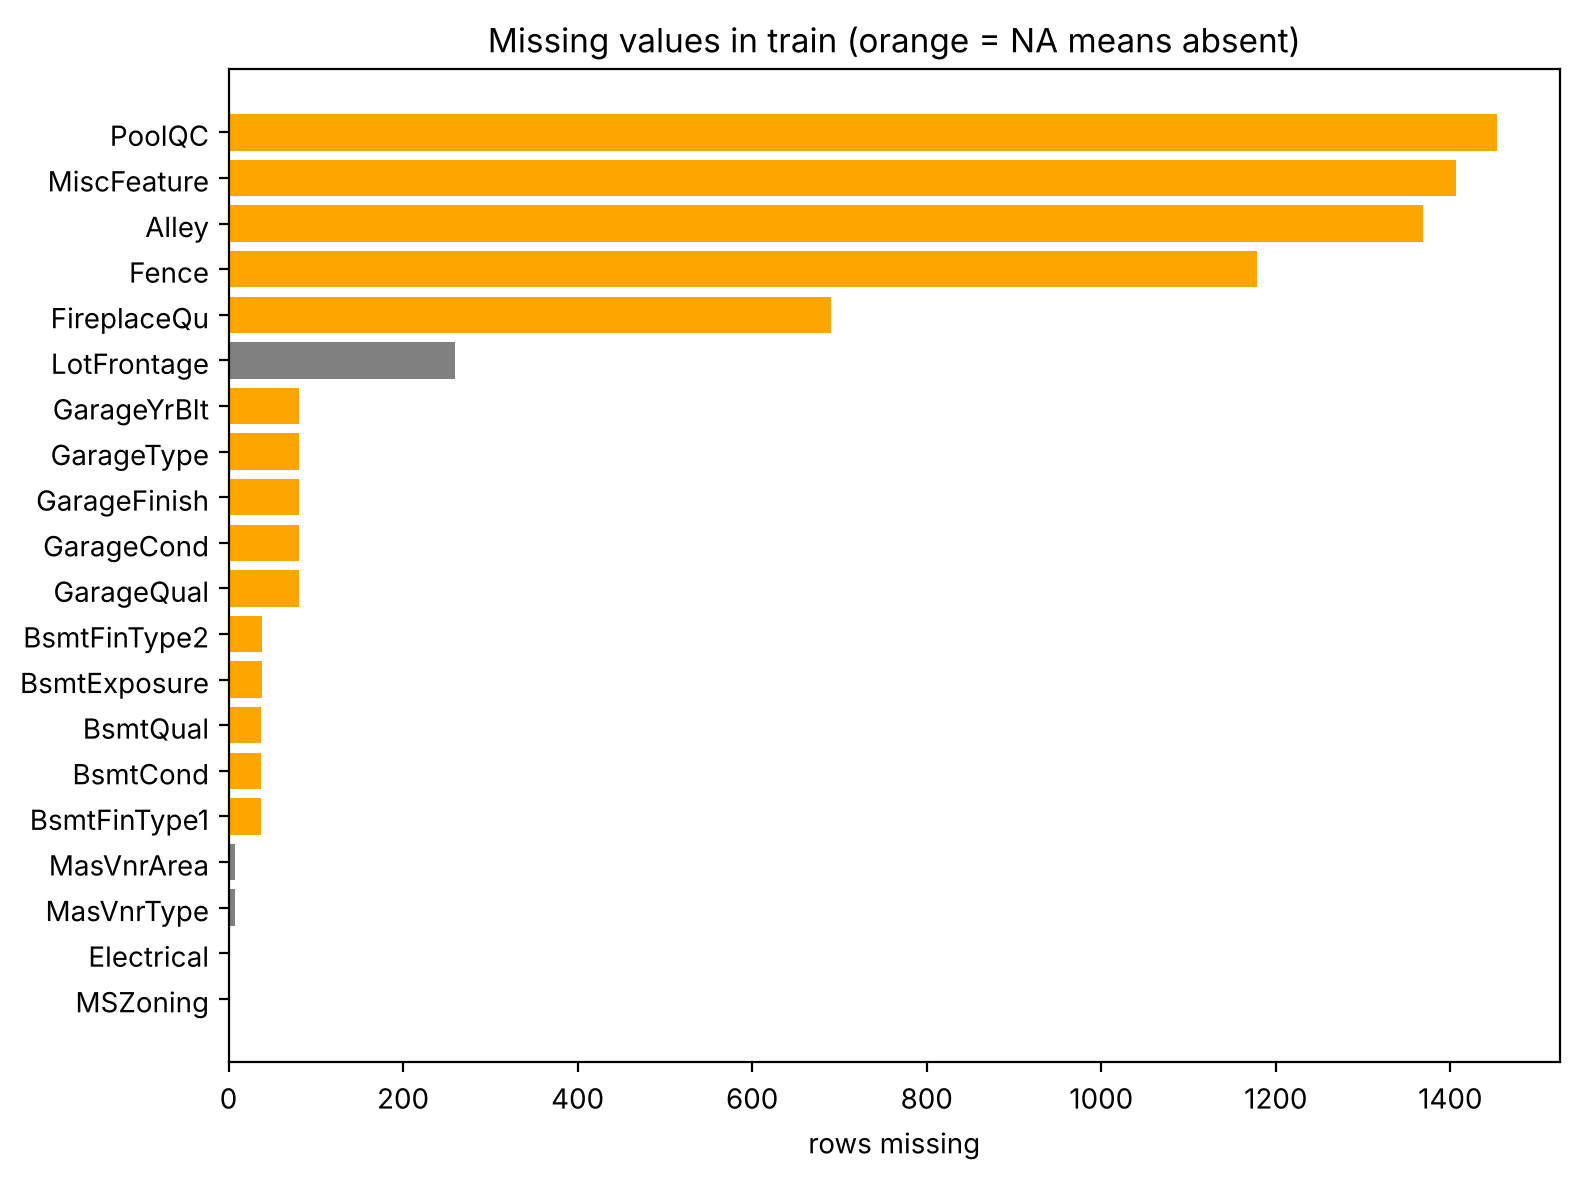

,train,test,kind
PoolQC,1453,1456,NA = absent
MiscFeature,1406,1408,NA = absent
Alley,1369,1352,NA = absent
Fence,1179,1169,NA = absent
FireplaceQu,690,730,NA = absent
LotFrontage,259,227,truly unknown
GarageYrBlt,81,78,NA = absent
GarageType,81,76,NA = absent
GarageFinish,81,78,NA = absent
GarageCond,81,78,NA = absent


In [4]:
ABSENT_MEANING = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
                  "GarageType", "GarageFinish", "GarageQual", "GarageCond", "GarageYrBlt",
                  "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]

missing = pd.DataFrame({"train": train.drop(columns="SalePrice").isna().sum(),
                        "test": test.isna().sum()})
missing = missing[(missing.train + missing.test) > 0]
missing["kind"] = np.where(missing.index.isin(ABSENT_MEANING), "NA = absent", "truly unknown")
missing = missing.sort_values("train", ascending=False)
print("Columns missing only in test:", missing.index[missing.train.eq(0)].tolist())

top = missing.head(20).iloc[::-1]
colors = np.where(top.kind.eq("NA = absent"), "orange", "gray")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.train, color=colors)
ax.set(title="Missing values in train (orange = NA means absent)", xlabel="rows missing")
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "02_missing_values.png", dpi=120)
plt.show()
missing

### 1.4 Outliers
Living area (`GrLivArea`) is one of the strongest predictors. But two houses are huge
(over 4,000 sq ft) yet sold cheaply (under $300k). Both were *Partial* sales of new builds,
so they don't follow the normal price pattern. A model that tries to fit them bends its
line for every other house. Part 3 (Step 6) tests removing them from training.

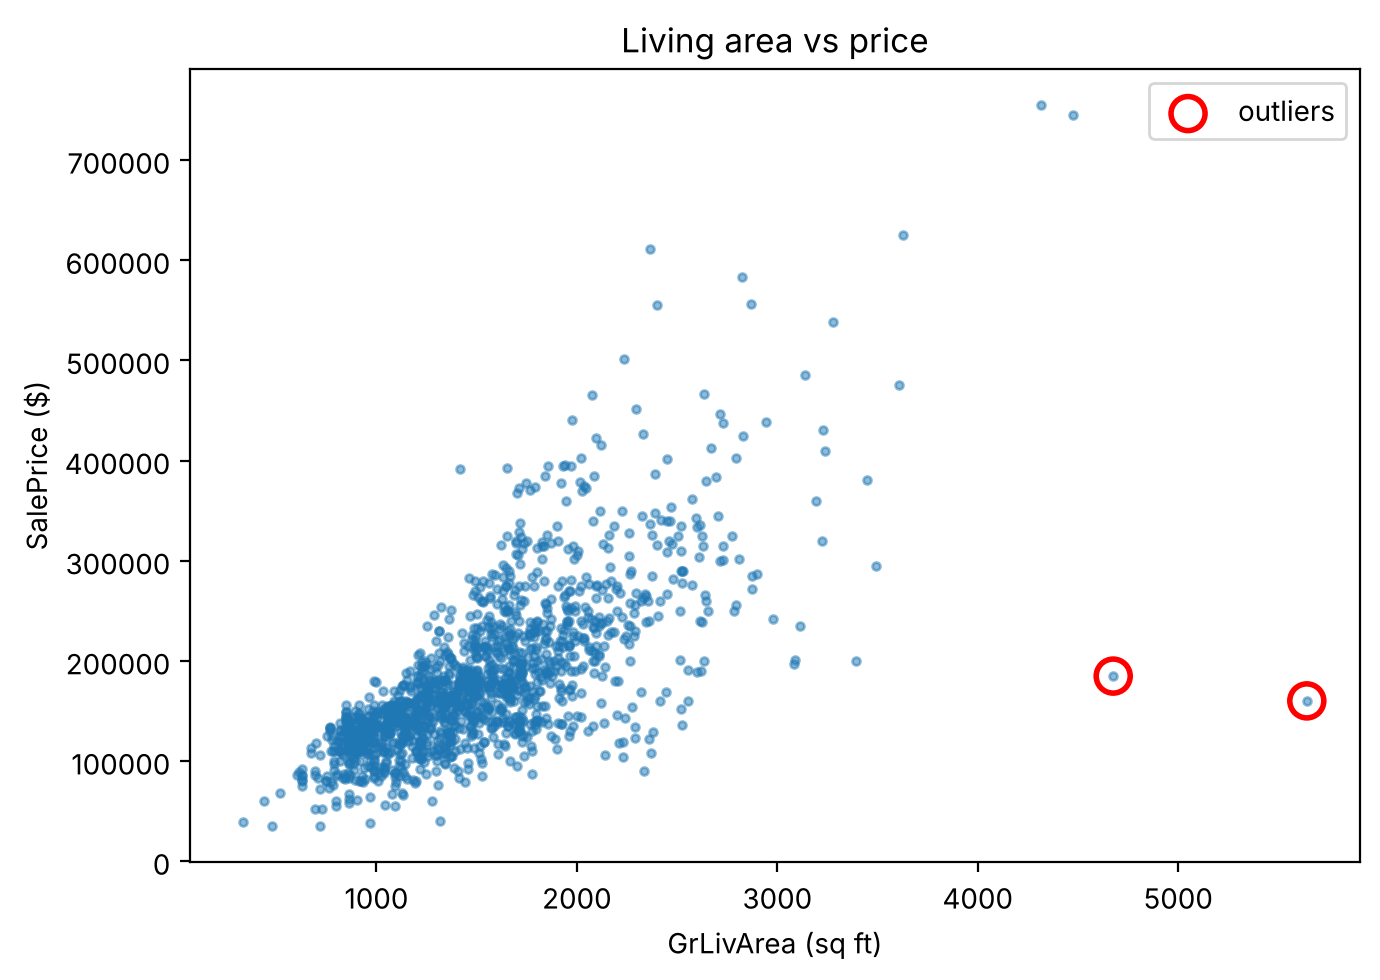

,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
1298,1299,5642,160000,10,Partial


In [5]:
outlier = (train.GrLivArea > 4000) & (train.SalePrice < 300000)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train.GrLivArea, train.SalePrice, s=8, alpha=0.5)
ax.scatter(train.GrLivArea[outlier], train.SalePrice[outlier], s=150,
           facecolors="none", edgecolors="red", linewidths=2, label="outliers")
ax.set(title="Living area vs price", xlabel="GrLivArea (sq ft)", ylabel="SalePrice ($)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "03_outliers.png", dpi=120)
plt.show()
train.loc[outlier, ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition"]]

### 1.5 Which numeric columns move with price?
Correlation only sees straight-line relationships, and it ignores the 43 text columns.
It is a quick map, not a feature-selection rule.

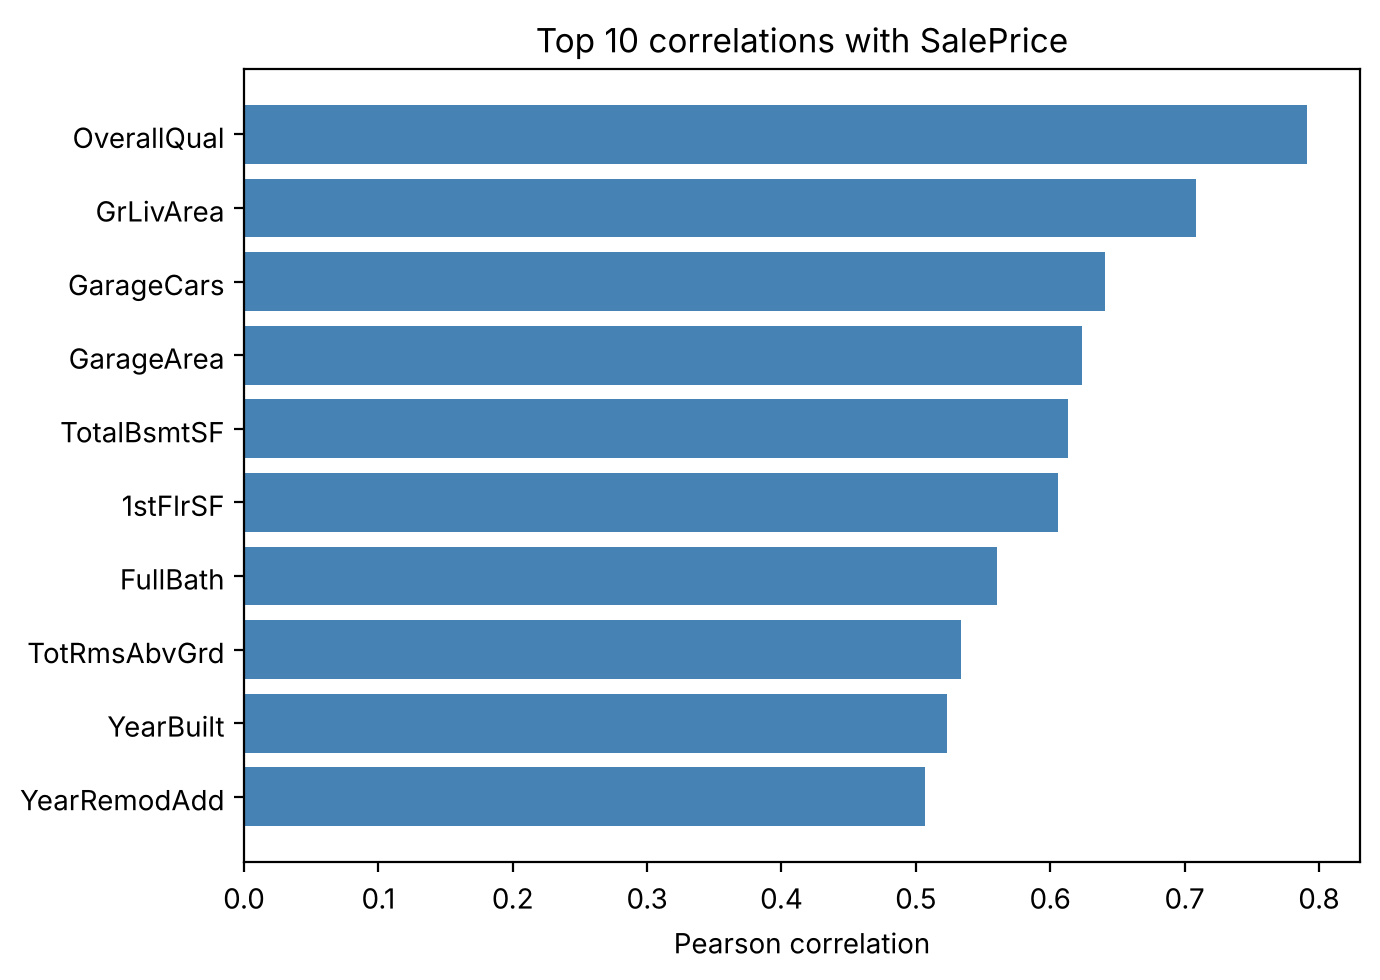

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

In [6]:
correlations = (train.select_dtypes("number").drop(columns="Id")
                .corr()["SalePrice"].drop("SalePrice").sort_values())
top10 = correlations.tail(10)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top10.index, top10.values, color="steelblue")
ax.set(title="Top 10 correlations with SalePrice", xlabel="Pearson correlation")
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "04_top_correlations.png", dpi=120)
plt.show()
top10.iloc[::-1].round(3)

### What EDA tells us to do next
| Finding | Action | Step |
|---|---|---|
| SalePrice is right-skewed; the metric is on log scale | Predict log(SalePrice) | Step 2 |
| Many NAs mean "doesn't have one" | Fill them with an explicit "absent" label | Step 3 |
| Quality and size dominate; size is spread across many columns | Build total-size and age features | Step 4 |
| Area columns are skewed like the price | Take log1p of skewed areas | Step 5 |
| Two huge-but-cheap houses | Test dropping them from training | Step 6 |

## Part 2: Baseline and cross-validation

### Why we need cross-validation (CV)
We can't score ourselves on `test`: its prices are hidden, and Kaggle limits daily
submissions. Scoring on the rows we trained on would be cheating, because the model has
already seen the answers. So we split `train` into **5 folds**. Each fold takes a turn as
"pretend test data", while a model is trained on the other 4. Every house is predicted exactly
once by a model that never saw it. These are the **out-of-fold (OOF)** predictions, and their
error is our **CV score**.

Every step in this notebook uses the **same 5 folds** (`random_state=42`), so differences
between steps come from our changes, not from luck in the split.

### Avoiding data leakage
Some preprocessing *learns from the data*. Filling gaps with the median, scaling, and
listing the categories for one-hot encoding all do. If we did those on all 1,460 rows before
splitting, every fold's "unseen" houses would already have influenced the training. That is
**data leakage**, and it makes CV look better than reality. Wrapping preprocessing and model
in one sklearn `Pipeline` means each fold re-learns the preprocessing from its own training
rows only.

In [7]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

kf = KFold(n_splits=5, shuffle=True, random_state=42)


def make_linear_preprocessor():
    """Numbers: fill gaps with the median, then scale. Text: fill gaps, then one-hot encode."""
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include="number")),
        ("cat", categorical, make_column_selector(dtype_exclude="number")),
    ])


def cv_evaluate(model, X, y, X_test, target="log", drop_outliers=False):
    """5-fold CV. Returns (cv_rmse, out-of-fold log predictions, averaged test log predictions)."""
    y = np.asarray(y, dtype=float)
    y_log = np.log(y)
    oof_log = np.zeros(len(X))
    test_log = np.zeros(len(X_test))
    for train_idx, valid_idx in kf.split(X):
        if drop_outliers:  # remove outliers from the training rows only; validation keeps them
            keep = ~((X.GrLivArea.values[train_idx] > 4000) & (y[train_idx] < 300000))
            train_idx = train_idx[keep]
        fold_model = clone(model)  # a fresh, untrained copy for every fold
        if target == "log":
            fold_model.fit(X.iloc[train_idx], y_log[train_idx])
            oof_log[valid_idx] = fold_model.predict(X.iloc[valid_idx])
            test_log += fold_model.predict(X_test) / kf.n_splits
        else:  # target == "raw": learn dollars, convert to log only for scoring
            fold_model.fit(X.iloc[train_idx], y[train_idx])
            floor = y[train_idx].min() / 2  # a raw-price model can predict <= 0; log needs > 0
            oof_log[valid_idx] = np.log(np.clip(fold_model.predict(X.iloc[valid_idx]), floor, None))
            test_log += np.log(np.clip(fold_model.predict(X_test), floor, None)) / kf.n_splits
    cv_rmse = np.sqrt(np.mean((y_log - oof_log) ** 2))
    return cv_rmse, oof_log, test_log


results = pd.DataFrame(columns=["step", "description", "cv_rmse"])


def record(step, description, cv_rmse):
    """Add one row to the results table, print the change, and save the table."""
    global results
    if len(results):
        change = cv_rmse - results.cv_rmse.iloc[-1]
        print(f"Step {step}: CV RMSE {cv_rmse:.5f} ({change:+.5f} vs previous step)")
    else:
        print(f"Step {step}: CV RMSE {cv_rmse:.5f}")
    row = pd.DataFrame([{"step": str(step), "description": description, "cv_rmse": cv_rmse}])
    results = row if results.empty else pd.concat([results, row], ignore_index=True)
    results.to_csv(OUT_DIR / "cv_results.csv", index=False)


def save_submission(name, test_log):
    """Turn log predictions back into dollars and write a Kaggle submission file."""
    submission = pd.DataFrame({"Id": test.Id, "SalePrice": np.exp(test_log)})
    assert len(submission) == 1459 and submission.Id.tolist() == sample.Id.tolist()
    assert np.isfinite(submission.SalePrice).all() and (submission.SalePrice > 0).all()
    (OUT_DIR / "submissions").mkdir(parents=True, exist_ok=True)
    submission.to_csv(OUT_DIR / "submissions" / f"{name}.csv", index=False)
    print("saved", name + ".csv")

### Step 0: predict the average price for every house
This is the "no model" reference point. Any real model must beat it.

In [8]:
X = train.drop(columns=["Id", "SalePrice"])
y = train.SalePrice
X_test = test.drop(columns="Id")

score, _, _ = cv_evaluate(DummyRegressor(strategy="mean"), X, y, X_test, target="raw")
record("0", "Predict the mean price", score)

Step 0: CV RMSE 0.40776


### Step 1: Ridge regression on the raw data
Ridge is linear regression with a penalty on large coefficients, $\alpha\sum_j \beta_j^2$.
With about 270 columns after one-hot encoding and only 1,460 houses, plain linear
regression would overfit. The penalty keeps the coefficients modest.

Here we train on **raw dollar prices** with only the minimum preprocessing. Every later step
changes one thing and is compared with this.

In [9]:
ridge_raw = Pipeline([("prep", make_linear_preprocessor()), ("model", Ridge(alpha=10))])
score, oof_step1, test_step1 = cv_evaluate(ridge_raw, X, y, X_test, target="raw")
record("1", "Ridge, raw price, minimal preprocessing", score)
save_submission("s1_ridge_raw", test_step1)

Step 1: CV RMSE 0.15534 (-0.25243 vs previous step)
saved s1_ridge_raw.csv


### Reading the numbers
A CV RMSE of 0.40 (Step 0) means a typical miss of about $e^{0.40}-1 \approx 49\%$.
Ridge cuts that to about 0.155, a typical miss of roughly 17%. But Step 1 still trains on
dollars while being scored in logs. Nothing stops a dollar model from predicting a price of
zero or less, so `cv_evaluate` puts a floor under raw predictions. It wasn't triggered here,
but it guards against a crash. Part 3 fixes this mismatch first.

In [10]:
results

,step,description,cv_rmse
0,0,Predict the mean price,0.407762
1,1,"Ridge, raw price, minimal preprocessing",0.155335
